# PathSnap — Exploratory Data Analysis

Member 1: Data, Candidates, Features and EDA

This notebook summarizes the dataset inventory, GPS quality, candidate generation, and provisional-label coverage.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path('..') if Path('../results').exists() else Path('.')
METRICS = ROOT / 'results' / 'metrics'
PLOTS = ROOT / 'results' / 'plots'
print('Project root:', ROOT.resolve())

Project root: D:\ML HACKATHON


## 1. Dataset inventory

In [2]:
inventory = pd.read_csv(METRICS / 'inventory.csv')
display(inventory.head())
print('Inventory rows:', len(inventory))

,partition,trip_id,gps_points,nodes,arcs,route_arcs,track_bytes,nodes_bytes,arcs_bytes,route_bytes
0,train,1,1315,88809,165790,525,40975,1687371,1948474,3119
1,train,2,7243,7936,16139,262,238085,158720,156519,1398
2,train,3,821,9138,18028,79,26164,182760,175733,411
3,train,4,1064,7350,15499,320,34982,147000,149738,1582
4,train,5,1045,898,1579,105,33378,17960,12351,421


Inventory rows: 90


## 2. GPS and road-network quality

In [3]:
quality = pd.read_csv(METRICS / 'quality_report.csv')
display(quality.head())
print('Quality-report rows:', len(quality))
display(quality.describe(include='all').T)

,partition,trip_id,track_dtype,nodes_dtype,arcs_dtype,missing_or_nonfinite,invalid_gps_coordinates,non_increasing_timestamps,gaps_over_120s,max_gap_seconds,min_longitude,max_longitude,min_latitude,max_latitude,weak_components,largest_component_nodes,isolated_nodes,directed_network,reference_links_disconnected
0,train,1,float64,float64,int64,0,0,0,0,16.0,8.570524,8.647860,49.844053,50.211882,175,86854,0,True,0
1,train,2,float64,float64,int64,0,0,0,3,160.0,10.999961,11.050902,47.658344,47.695459,14,7750,0,True,1
2,train,3,float64,float64,int64,0,0,0,0,2.0,37.154202,37.201595,55.977135,56.007585,42,8625,0,True,0
3,train,4,float64,float64,int64,0,0,0,0,51.0,12.342280,12.459615,52.590308,52.718960,12,7254,0,True,0
4,train,5,float64,float64,int64,0,0,0,0,1.0,35.485577,35.544315,49.357581,49.613085,3,888,0,True,0


Quality-report rows: 90


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
partition,90,2,train,80,NaN,NaN,NaN,NaN,NaN,NaN,NaN
trip_id,90.0,NaN,NaN,NaN,49.288889,29.15601,0.0,25.25,49.0,74.75,99.0
track_dtype,90,1,float64,90,NaN,NaN,NaN,NaN,NaN,NaN,NaN
nodes_dtype,90,1,float64,90,NaN,NaN,NaN,NaN,NaN,NaN,NaN
arcs_dtype,90,1,int64,90,NaN,NaN,NaN,NaN,NaN,NaN,NaN
missing_or_nonfinite,90.0,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0
invalid_gps_coordinates,90.0,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0
non_increasing_timestamps,90.0,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0
gaps_over_120s,90.0,NaN,NaN,NaN,0.466667,1.423716,0.0,0.0,0.0,0.0,11.0
max_gap_seconds,90.0,NaN,NaN,NaN,2408.522222,16996.219986,1.0,1.0,7.0,67.25,153064.0


## 3. Candidate feature generation

In [4]:
report = pd.read_csv(
    METRICS / 'feature_build_report.csv'
)
display(report.groupby('split').agg(
    trips=('trip_id', 'count'),
    gps_observations=('gps_observations', 'sum'),
    candidate_rows=('candidate_rows', 'sum')
))

,trips,gps_observations,candidate_rows
split,,,
student_test,10,19160,366616
train,80,208417,3248982


## 4. Provisional-label coverage

Labels are produced by heuristic alignment to reference-route arcs. They are not independently verified ground truth.

In [5]:
train = report[report['split'] == 'train'].copy()
train['trip_id'] = train['trip_id'].astype(str).str.zfill(8)
overall = (
    train['positive_labels'].sum()
    / train['gps_observations'].sum()
)
print(f'Observation-weighted coverage: {overall:.2%}')
print('Lowest-coverage trips:')
display(train.nsmallest(10, 'candidate_coverage')[['trip_id', 'gps_observations', 'candidate_coverage']])

Observation-weighted coverage: 90.04%
Lowest-coverage trips:


,trip_id,gps_observations,candidate_coverage
44,00000054,19313,0.153161
26,00000033,5844,0.463552
1,00000002,7243,0.904183
75,00000095,1551,0.948420
11,00000014,448,0.957589
60,00000075,1628,0.959459
35,00000043,2322,0.967270
40,00000048,1240,0.971774
49,00000061,1430,0.974126
55,00000069,2067,0.977746


## 5. Candidate configuration sweep

In [6]:
sweep = pd.read_csv(METRICS / 'candidate_sweep.csv')
display(sweep.sort_values('miss_rate').head(10))

,search_k,k,radius_m,observations,coverage,miss_rate
59,500,30,100,16000,0.976875,0.023125
39,300,30,100,16000,0.976562,0.023438
54,500,20,100,16000,0.973875,0.026125
34,300,20,100,16000,0.973688,0.026312
19,100,30,100,16000,0.972313,0.027687
58,500,30,50,16000,0.971313,0.028687
38,300,30,50,16000,0.971000,0.029000
53,500,20,50,16000,0.969375,0.030625
14,100,20,100,16000,0.969313,0.030687
33,300,20,50,16000,0.969187,0.030812


## 6. EDA plots

eda_trip_sizes.png


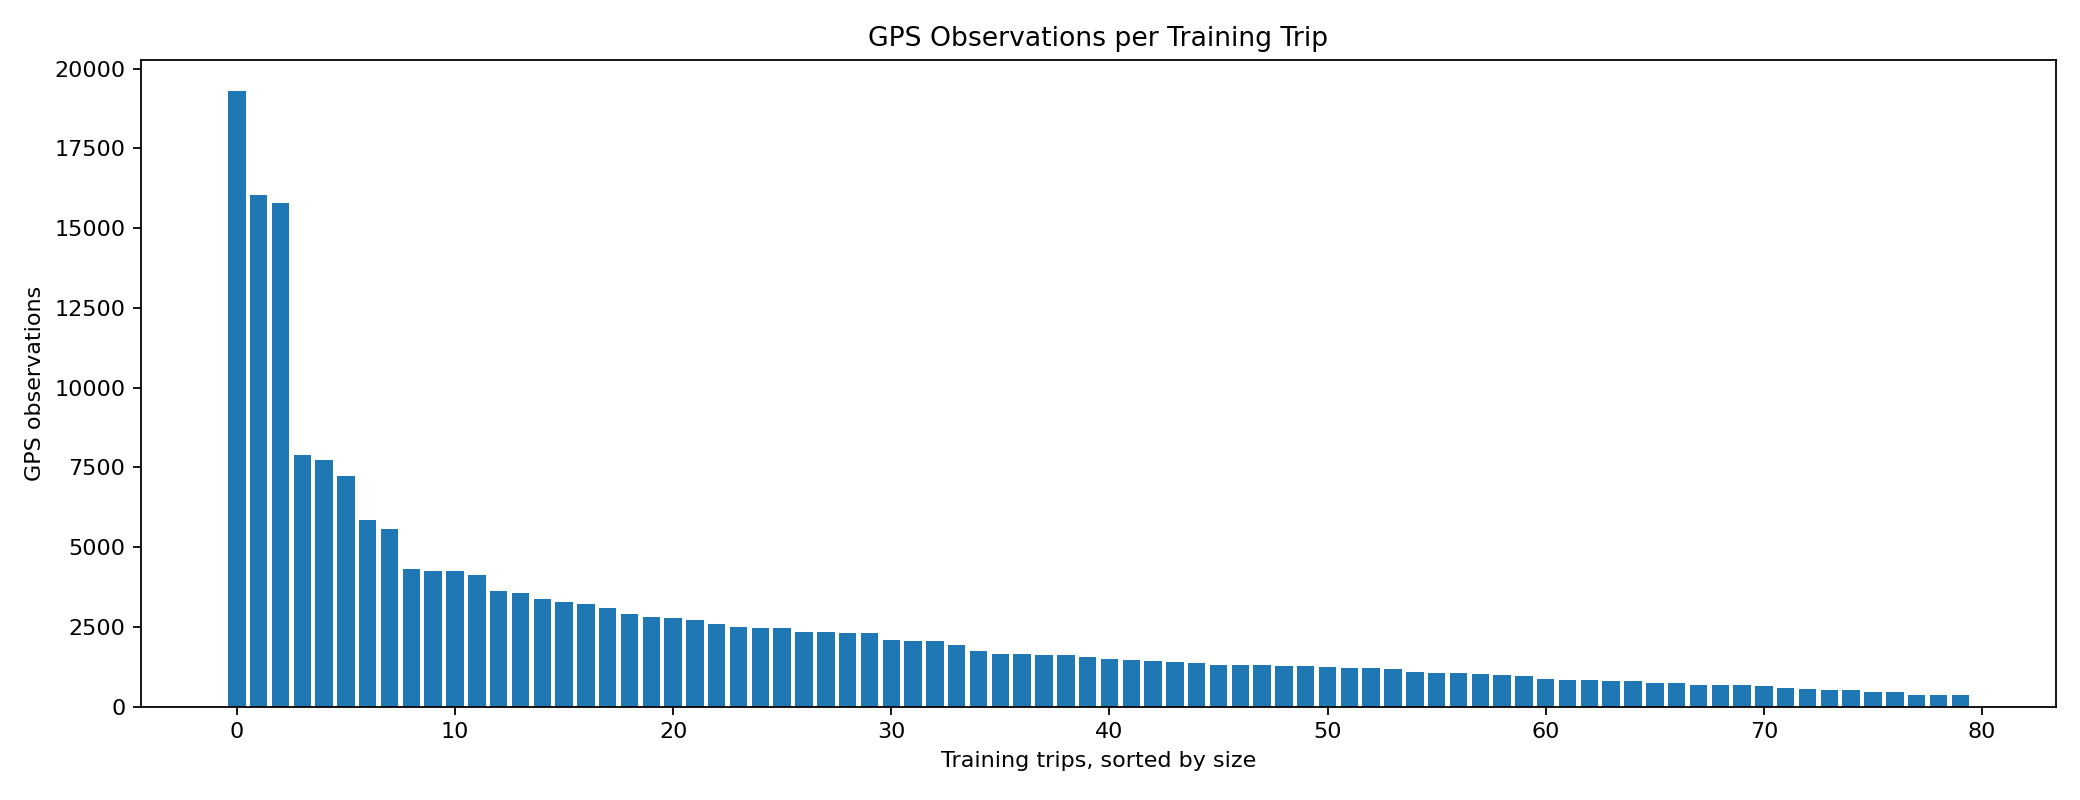

eda_candidate_coverage.png


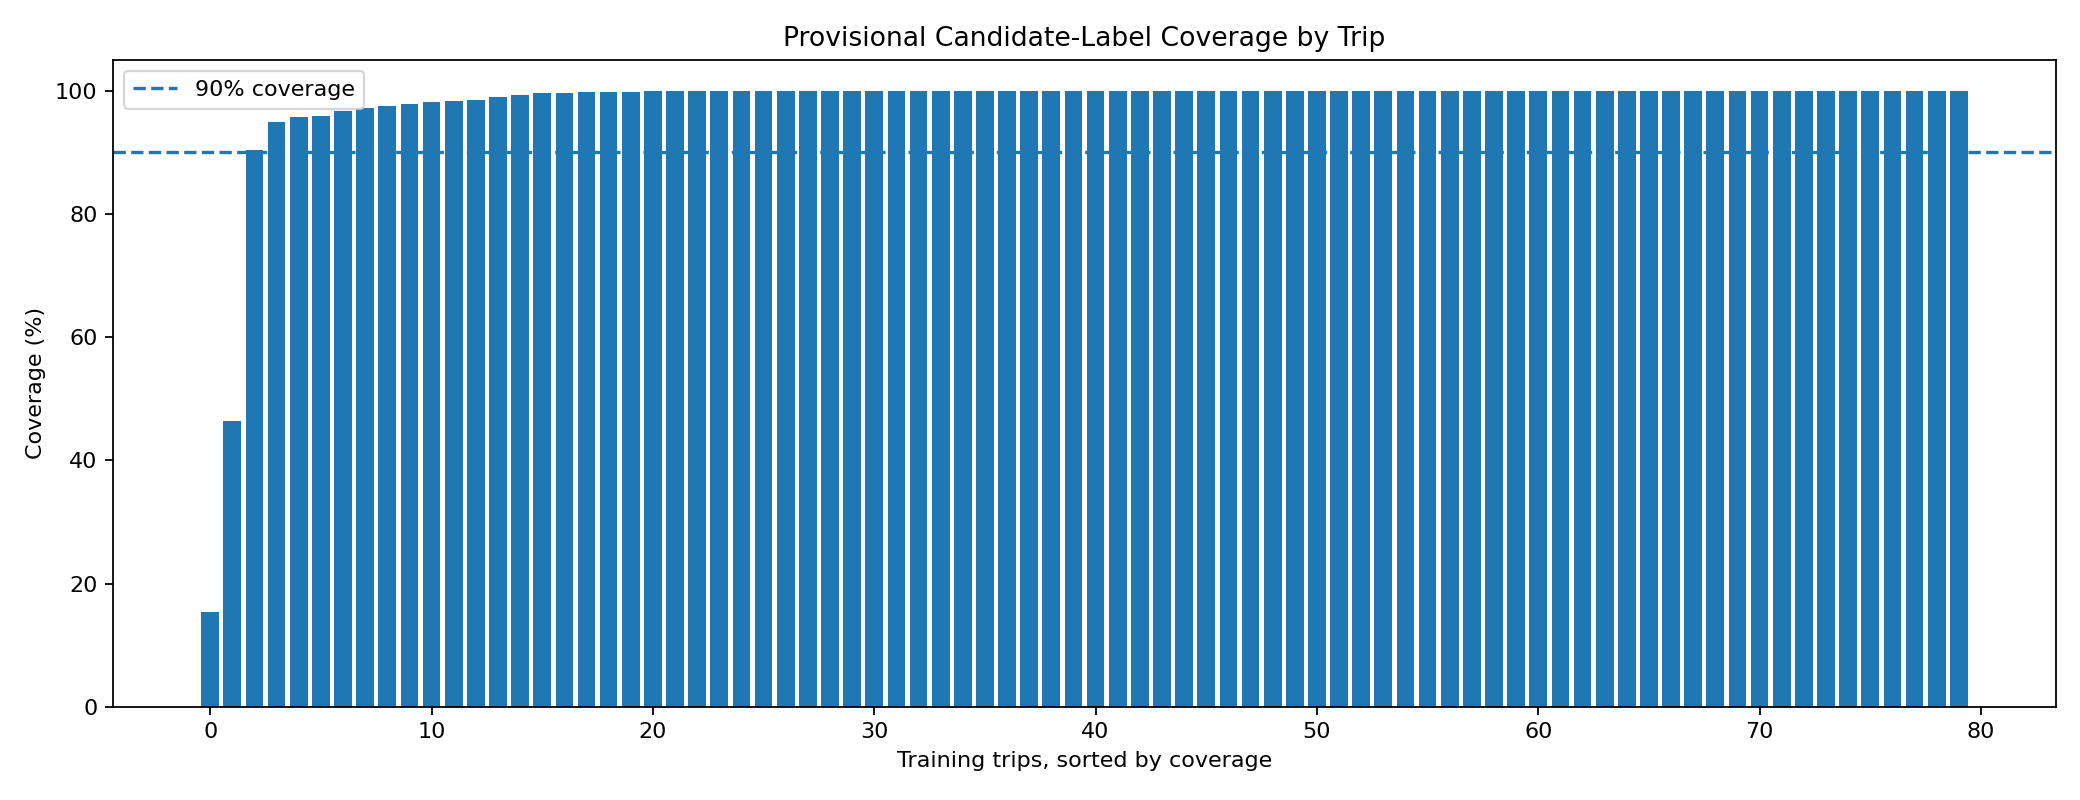

eda_candidate_distances.png


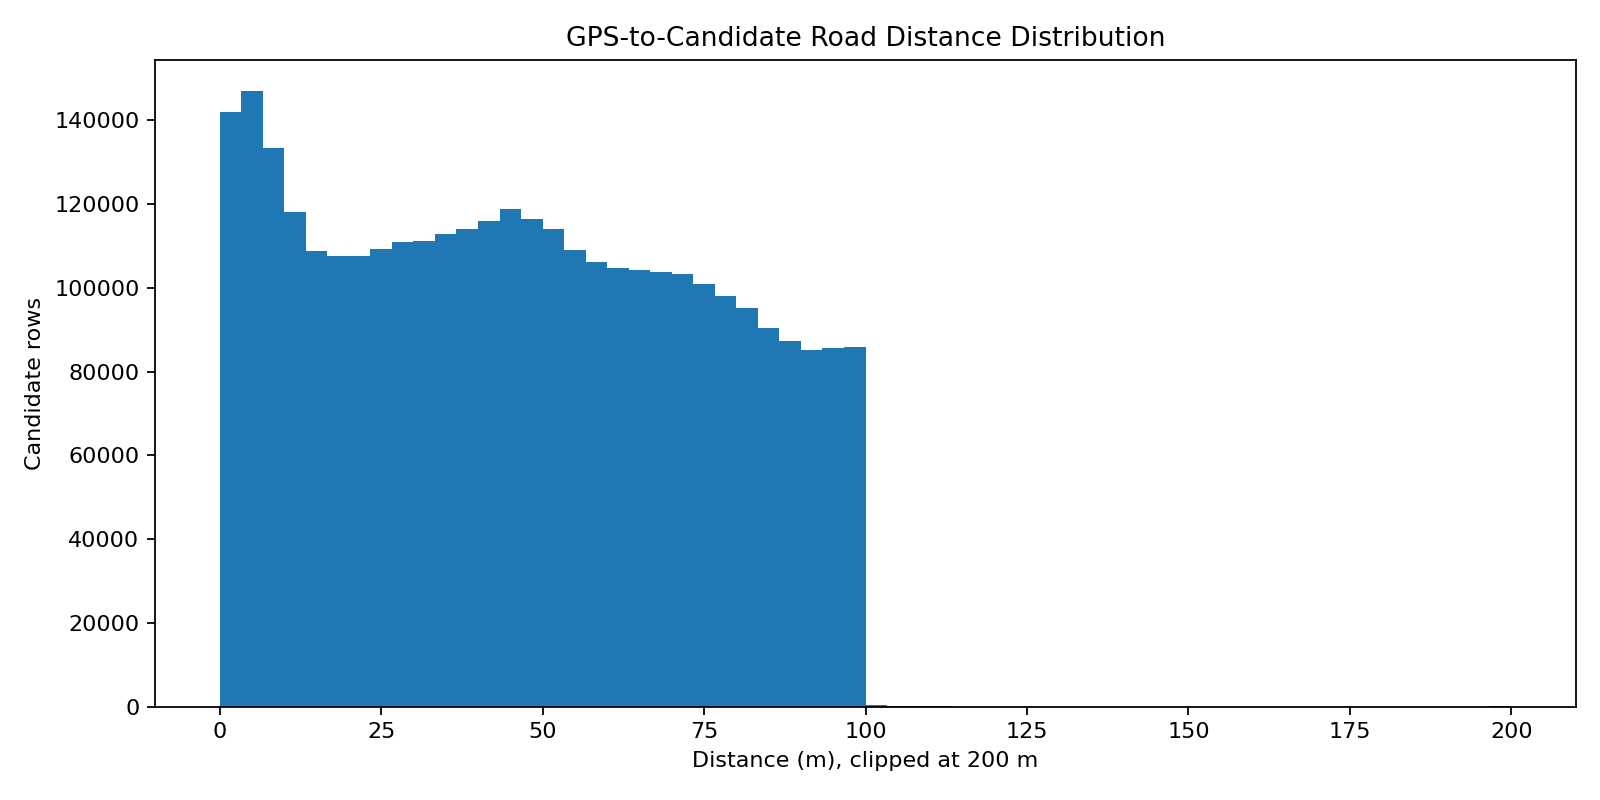

In [7]:
from IPython.display import Image, display

for filename in [
    'eda_trip_sizes.png',
    'eda_candidate_coverage.png',
    'eda_candidate_distances.png'
]:
    print(filename)
    display(Image(filename=str(PLOTS / filename)))

## 7. Interactive route maps

Open the generated HTML maps in a browser:

- `maps/eda_trip_00000001.html`
- `maps/eda_trip_00000033.html`
- `maps/eda_trip_00000054.html`

Blue shows the GPS trajectory; red shows the reference road arcs.

## 8. Findings and limitations

- The dataset contains 80 training trips and 10 student-test trips.
- Candidate features use a per-trip local metric projection.
- The baseline uses up to 30 candidates within 100 metres per GPS observation.
- Training labels are provisional route-aligned arc assignments.
- Trips 33 and 54 have particularly low candidate-label coverage.
- Increasing candidate count and radius improves recall on sampled observations, but increases computation.
- Student-test reference routes are not used to construct model input features.